# Frozen embeddings on quarterly splits

Rank historically popular, unseen recipes using frozen name/ingredient representations.
Generate MiniLM inputs once with `python scripts/embed_recipes.py --device mps`.

`centered` averages separate name/ingredient cosine scores after subtracting the available catalog mean.
`tfidf` uses a weighted name/ingredient TF-IDF history average, fit on the available catalog each quarter.
`top3` averages similarity to the three closest liked recipes, rather than one average user vector.
Ratings 5★=1, 4★=0.5; other ratings do not contribute. Popularity supplies candidates and fallback only.

In [1]:
# Optional if you have trouble running the environment.
import sys
sys.path.insert(0, "../src")
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from remy.splits import RollingSplits, SPLIT_DIR
from remy.evaluate import evaluate_quarter
from remy.model.embedding import EmbeddingRecommender, load_embeddings

In [2]:
splits = RollingSplits()
split = "val"
model_kwargs = dict(method="centered", n_candidates=1000)
embeddings = load_embeddings()
eval_quarters = splits.evaluation_quarters(split)
assert len(eval_quarters) == 16
assert np.array_equal(embeddings["id"], splits.recipes.sort_values("id").id.to_numpy())
output = SPLIT_DIR / f"embedding_{model_kwargs['method']}_{model_kwargs['n_candidates']}_{split}.csv"

splits.windows.groupby("split", sort=False)[
    ["outcome_reviews", "positive_reviews", "positive_users"]
].sum().rename(columns={"positive_users": "positive_user_quarters"})

,outcome_reviews,positive_reviews,positive_user_quarters
split,,,
train,138126,106422,19880
val,377717,279537,61814
test,134059,100846,29079


## Fit and evaluate

Create a fresh model at each cutoff; outcomes are used only for scoring.
This cell runs all 16 validation quarters and saves after each quarter.

In [3]:
rows = []
total_start = time.perf_counter()
for quarter in eval_quarters:
    quarter_start = time.perf_counter()
    assert (quarter.history.date < quarter.start).all()
    assert (quarter.recipes.submitted < quarter.start).all()
    model = EmbeddingRecommender(embeddings=embeddings, **model_kwargs)
    model.fit(quarter.history, recipes=quarter.recipes)
    users = quarter.outcomes.loc[quarter.outcomes.rating == 5, "user_id"].unique()
    recs = model.recommend_many(users)
    assert set(model.candidates_).issubset(set(quarter.recipes.id))
    assert all(not set(ids) & model.seen_.get(user, set()) for user, ids in recs.items())
    rows.append(evaluate_quarter(quarter, model.ranking_, model.seen_, recs))
    pd.DataFrame(rows).to_csv(output, index=False)
    print(f"Finished {quarter.start.date()} in {(time.perf_counter() - quarter_start) / 60:.2f} min "
          f"(total: {(time.perf_counter() - total_start) / 60:.2f} min)")

results = pd.DataFrame(rows)

Finished 2007-01-01 in 0.05 min (total: 0.05 min)


Finished 2007-04-01 in 0.04 min (total: 0.08 min)


Finished 2007-07-01 in 0.04 min (total: 0.12 min)


Finished 2007-10-01 in 0.04 min (total: 0.16 min)


Finished 2008-01-01 in 0.05 min (total: 0.21 min)


...

Finished 2009-10-01 in 0.06 min (total: 0.58 min)


Finished 2010-01-01 in 0.06 min (total: 0.64 min)


Finished 2010-04-01 in 0.06 min (total: 0.70 min)


Finished 2010-07-01 in 0.05 min (total: 0.75 min)


Finished 2010-10-01 in 0.05 min (total: 0.79 min)


## Results

NDCG measures the full ranking, including the evaluator's popularity fallback.
Candidate recall is the share of positive reviews in the personalized ranking.

In [4]:
metrics = ["NDCG", "HR@10", "HR@100", "Recall@10", "Recall@100", "candidate_recall"]
results[metrics].mean().to_frame("Mean across quarters").round(4)

,Mean across quarters
NDCG,0.1190
HR@10,0.0187
HR@100,0.1154
Recall@10,0.0068
Recall@100,0.0452
candidate_recall,0.1538


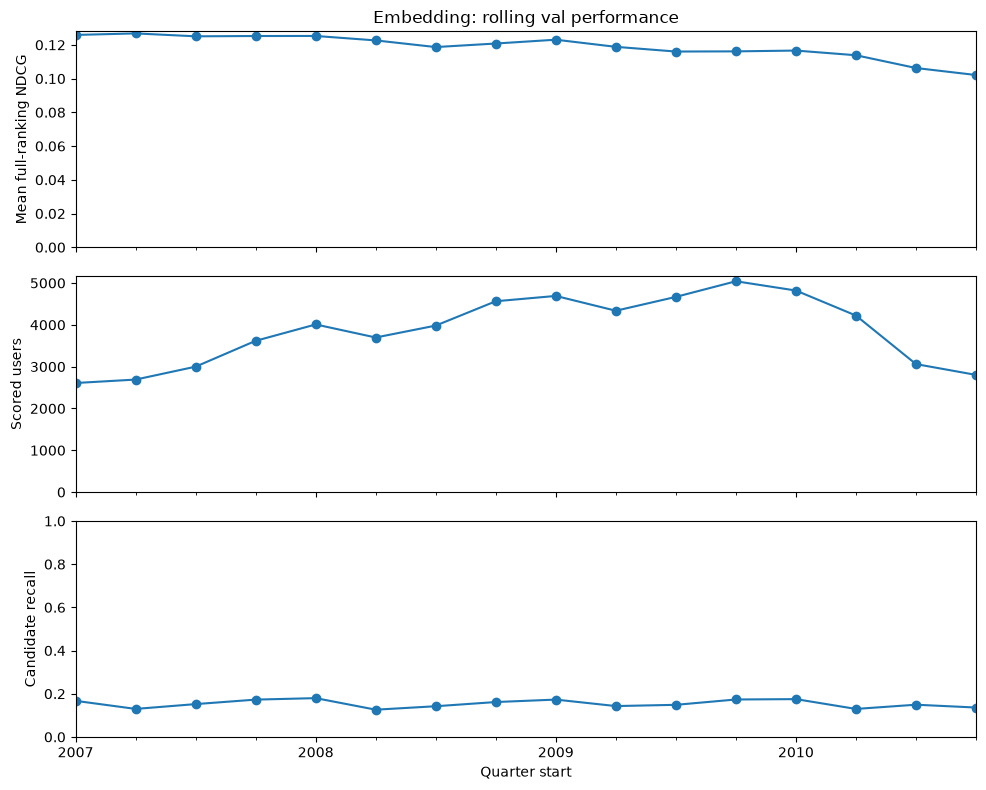

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
results.plot(x="start", y="NDCG", marker="o", legend=False, ax=axes[0])
axes[0].set(title=f"Embedding: rolling {split} performance", ylabel="Mean full-ranking NDCG")
axes[0].set_ylim(bottom=0)
results.plot(x="start", y="scored_users", marker="o", legend=False, ax=axes[1])
axes[1].set(ylabel="Scored users")
axes[1].set_ylim(bottom=0)
results.plot(x="start", y="candidate_recall", marker="o", legend=False, ax=axes[2])
axes[2].set(ylabel="Candidate recall", xlabel="Quarter start")
axes[2].set_ylim(0, 1)
fig.tight_layout()
plt.show()